In [126]:
%%time
dataset_name = "W30_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (12866, 13)
old_new_col_names not loaded
CPU times: total: 27.1 s
Wall time: 27.8 s


In [227]:
%%time
dataset_name = "W28_only"
df_list = "BES_reduced_with_na"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (576, 13)
CPU times: total: 2.55 s
Wall time: 2.79 s


<Figure size 640x480 with 0 Axes>

In [ ]:
## get maxLikedParty
## get whether it's tied

In [229]:
# search(BES_Panel,"ptvCon")
# ptvConW27     7639
# ptvConW30     7687

In [11]:
search(BES_Panel,"like(Con|Lab|LD|BrexitParty|Grn)W28|p_past_vote_2024|countryW28")


# make life easier - England, 

mapConW3               15152
leaveVoteUKIPConW7      7682
leaveVoteUKIPConW8      6106
pContactEday_10W13     14108
pContactEday_1W13      10234
                       ...  
pcon_codeW26          122372
pcon_codeW24          122372
pcon_codeW29          122372
pcon_codeW30          122372
p_past_vote_2024       35427
Length: 153, dtype: int64

In [8]:

BES_Panel["p_past_vote_2024"][England].value_counts()

# vote = Lab/Con/REFUK/LD/Grn/OTH/IND/DK
England = (BES_Panel["countryW28"]=="England")


p_past_vote_2024
Labour                           6930
Conservative                     5004
Brexit Party/Reform UK           3406
Liberal Democrat                 2873
Green Party                      1433
Other                             383
An independent candidate          300
Don't know                        260
Scottish National Party (SNP)       0
Plaid Cymru                         0
Name: count, dtype: int64

In [18]:
like_df = BES_Panel[search(BES_Panel,"like(Con|Lab|LD|BrexitParty|Grn)W28").index].apply(lambda x:x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))


In [61]:
replace_dict = {'likeConW28':"CON", 'likeLabW28':"LAB", 'likeLDW28':"LD", 'likeBrexitPartyW28':"REFUK",
       'likeGrnW28':"GP"}
like_df["maxParty"] = like_df[replace_dict.keys()].apply(lambda x:x + np.random.rand(len(x))*.1 ).idxmax(axis=1).apply(lambda x: np.nan if pd.isna(x) else replace_dict[x])
like_df["max"] = like_df[replace_dict.keys()].max(axis=1)
#  = 
like_df["untied_lead"] = like_df[replace_dict.keys()].apply(lambda x: x==like_df["max"]).sum(axis=1)==1
# like_df.sum()
like_df["untied_lead"].sum()
like_df["maxParty_untied"] = like_df["maxParty"]
like_df.loc[~like_df["untied_lead"],"maxParty_untied"]=np.nan
# non_deterministic!

In [32]:
like_df.dropna()

,likeConW28,likeLabW28,likeLDW28,likeBrexitPartyW28,likeGrnW28,max
id,,,,,,
6,0.0,8.0,4.0,0.0,5.0,LAB
7,0.0,3.0,4.0,3.0,3.0,LD
11,8.0,0.0,0.0,0.0,0.0,CON
14,9.0,1.0,0.0,0.0,0.0,CON
18,0.0,3.0,4.0,0.0,7.0,GP
...,...,...,...,...,...,...
117889,7.0,3.0,5.0,6.0,3.0,CON
117897,3.0,6.0,7.0,0.0,6.0,LD
117903,0.0,6.0,6.0,0.0,8.0,GP


In [67]:
BES_Panel["p_past_vote_2024"][England].groupby(like_df["maxParty"][England]).value_counts(normalize=True).round(2)

maxParty  p_past_vote_2024             
CON       Conservative                     0.79
          Brexit Party/Reform UK           0.07
          Liberal Democrat                 0.05
          Labour                           0.04
          An independent candidate         0.02
          Don't know                       0.01
          Green Party                      0.01
          Other                            0.01
          Scottish National Party (SNP)    0.00
          Plaid Cymru                      0.00
GP        Labour                           0.40
          Green Party                      0.28
          Liberal Democrat                 0.17
          Conservative                     0.06
          Other                            0.03
          Brexit Party/Reform UK           0.02
          An independent candidate         0.02
          Don't know                       0.01
          Scottish National Party (SNP)    0.00
          Plaid Cymru                      0.00


In [68]:
BES_Panel["p_past_vote_2024"][England].groupby(like_df["maxParty_untied"][England]).value_counts(normalize=True).round(2)

maxParty_untied  p_past_vote_2024             
CON              Conservative                     0.84
                 Brexit Party/Reform UK           0.04
                 Liberal Democrat                 0.04
                 Labour                           0.03
                 An independent candidate         0.01
                 Don't know                       0.01
                 Other                            0.01
                 Green Party                      0.01
                 Scottish National Party (SNP)    0.00
                 Plaid Cymru                      0.00
GP               Labour                           0.38
                 Green Party                      0.34
                 Liberal Democrat                 0.15
                 Conservative                     0.04
                 Other                            0.03
                 An independent candidate         0.02
                 Brexit Party/Reform UK           0.01
                 D

In [174]:
like_df["maxParty_untied"][England].value_counts(dropna=False)

maxParty_untied
NaN      6160
LAB      5082
CON      4611
REFUK    4401
GP       3883
LD       2075
Name: count, dtype: int64

In [ ]:
## Look at the maxParty_untied==LD in seats where there was no LD contention

In [178]:
LD_Contention = (BES_Panel[["Winner24","Second24","Winner19","Second19"]]=="LD").any(axis=1)

In [189]:
mask = (like_df["maxParty_untied"]=="LD") & (~LD_Contention) & England
BES_Panel["p_past_vote_2024"][mask].groupby(BES_Panel["reasonForVoteW29"][mask]).value_counts().head(50)

reasonForVoteW29                                                                       p_past_vote_2024             
None of these                                                                          Liberal Democrat                  25
                                                                                       Other                              3
                                                                                       An independent candidate           3
                                                                                       Don't know                         3
                                                                                       Conservative                       2
                                                                                       Labour                             2
                                                                                       Brexit Party/Reform UK             2
               

In [192]:
BES_Panel["p_past_vote_2024"][mask].value_counts()

p_past_vote_2024
Liberal Democrat                 594
Labour                           368
Conservative                      88
Green Party                       28
Other                             22
Brexit Party/Reform UK            21
An independent candidate          17
Don't know                        10
Scottish National Party (SNP)      0
Plaid Cymru                        0
Name: count, dtype: int64

In [ ]:
like_df["likeLibLabGapW28"] = like_df["likeLabW28"]-like_df["likeLDW28"]

<Axes: >

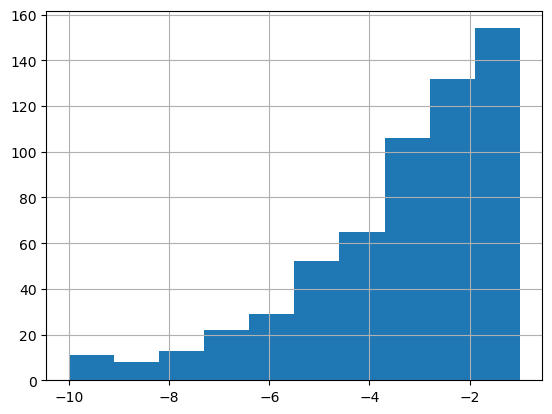

In [209]:
like_df[mask][ BES_Panel["p_past_vote_2024"][mask] == "Liberal Democrat"]["likeLibLabGapW28"].hist()

<Axes: >

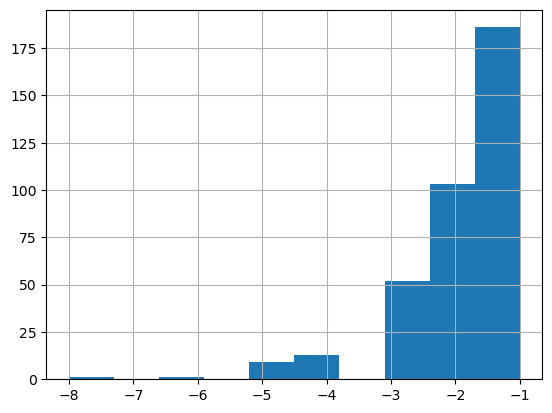

In [210]:
like_df[mask][ BES_Panel["p_past_vote_2024"][mask] == "Labour"]["likeLibLabGapW28"].hist()

<Axes: >

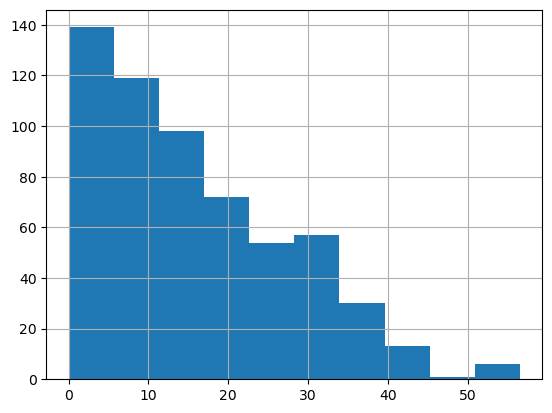

In [225]:
BES_Panel[mask][ BES_Panel["p_past_vote_2024"][mask] == "Liberal Democrat"]["Majority24"].hist()

<Axes: >

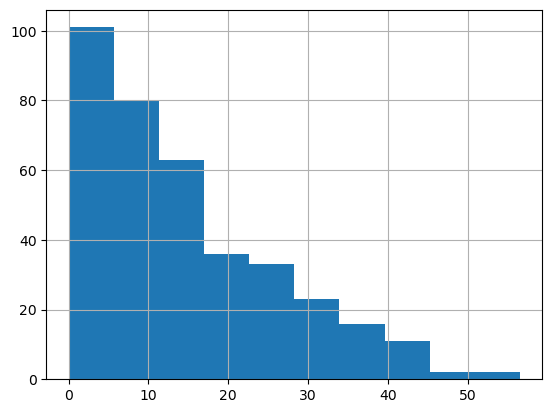

In [226]:
BES_Panel[mask][ BES_Panel["p_past_vote_2024"][mask] == "Labour"]["Majority24"].hist()

<Axes: >

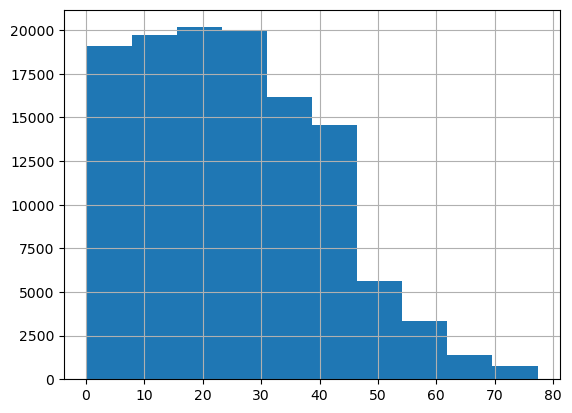

In [214]:
BES_Panel["Majority19"].hist()

In [69]:
search(BES_Panel,"reasonForVote")

reasonForVoteW6     27837
reasonForVoteW13    28293
reasonForVoteW19    28900
reasonForVoteW29    26997
dtype: int64

In [77]:
BES_Panel["reasonForVoteW29"].value_counts()

reasonForVoteW29
I thought it was the best party                                                          11188
I always vote that way                                                                    4135
I thought that party had the best candidate                                               3623
I really preferred another party but it had no chance of winning in this constituency     3362
Other                                                                                     3319
None of these                                                                             1042
Don't know                                                                                 328
Name: count, dtype: int64

In [79]:
BES_Panel["reasonForVoteW29"][England][ (like_df["maxParty_untied"][England]=="LAB") & (BES_Panel["p_past_vote_2024"][England]=="Liberal Democrat")]\
    .value_counts()

reasonForVoteW29
I really preferred another party but it had no chance of winning in this constituency    171
Other                                                                                     33
I thought it was the best party                                                           25
I thought that party had the best candidate                                               22
None of these                                                                              3
I always vote that way                                                                     1
Don't know                                                                                 0
Name: count, dtype: int64

In [81]:
BES_Panel["reasonForVoteW29"][England][ (like_df["maxParty_untied"][England]=="LD") & (BES_Panel["p_past_vote_2024"][England]=="Labour")]\
    .value_counts()

reasonForVoteW29
I really preferred another party but it had no chance of winning in this constituency    165
I thought it was the best party                                                           87
Other                                                                                     51
I thought that party had the best candidate                                               40
I always vote that way                                                                     7
None of these                                                                              2
Don't know                                                                                 1
Name: count, dtype: int64

In [82]:
BES_Panel["reasonForVoteW29"][England][ (like_df["maxParty_untied"][England]=="GP") & (BES_Panel["p_past_vote_2024"][England]=="Labour")]\
    .value_counts()

reasonForVoteW29
I really preferred another party but it had no chance of winning in this constituency    407
I thought it was the best party                                                          321
Other                                                                                    107
I thought that party had the best candidate                                               98
I always vote that way                                                                    97
None of these                                                                             18
Don't know                                                                                 5
Name: count, dtype: int64

In [83]:
BES_Panel["reasonForVoteW29"][England][ (like_df["maxParty_untied"][England]=="GP") & (BES_Panel["p_past_vote_2024"][England]=="Liberal Democrat")]\
    .value_counts()

reasonForVoteW29
I really preferred another party but it had no chance of winning in this constituency    171
I thought it was the best party                                                           94
I thought that party had the best candidate                                               73
Other                                                                                     73
None of these                                                                             15
I always vote that way                                                                     8
Don't know                                                                                 1
Name: count, dtype: int64

In [85]:
census2024 = pd.read_stata("C:\\Users\\Gamer\\Downloads\\BES-2024-General-Election-results-file-v1.0.dta")

In [86]:
census2024

,ONSConstID,ConstituencyName,Country,Region,ConstituencyType,Winner24,Second24,Con24,Lab24,LD24,...,c21NoWelsh,c21LanguageSomeEnglish,c21LanguageLimitedtoNoEnglish,c21ChurchofScotland,c21Catholic,c21NoQuals,c21LowerSchool,c21UpperSchool,c21Level4plus,c21Apprenticeship
0,W07000081,Aberafan Maesteg,Wales,Wales,County,Lab,RUK,8.119144,49.889526,2.561879,...,84.5,NaN,NaN,NaN,NaN,27.000000,24.800000,1.590000e+01,23.700000,5.900000
1,E14001063,Aldershot,England,South East,Borough,Lab,Con,29.006674,40.713579,8.347067,...,NaN,NaN,NaN,NaN,NaN,17.700000,26.300000,1.740000e+01,29.900000,5.700000
2,E14001064,Aldridge-Brownhills,England,West Midlands,Borough,Con,Lab,38.866347,28.370649,4.289695,...,NaN,NaN,NaN,NaN,NaN,21.900000,24.900000,1.720000e+01,27.200000,6.000000
3,E14001065,Altrincham and Sale West,England,North West,Borough,Lab,Con,32.309726,40.422141,9.187204,...,NaN,NaN,NaN,NaN,NaN,11.500000,19.400000,1.410000e+01,48.700000,4.400000
4,W07000082,Alyn and Deeside,Wales,Wales,County,Lab,RUK,18.187684,42.392607,4.758942,...,84.2,NaN,NaN,NaN,NaN,19.000000,25.800000,1.810000e+01,27.400000,6.700000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
627,S14000103,Perth and Kinross-shire,Scotland,Scotland,County,SNP,Con,29.556483,18.008267,7.350680,...,NaN,99.0,1.0,23.6,8.4,14.205994,17.703450,9.516133e+05,35.960244,7.612871
628,S14000104,Rutherglen,Scotland,Scotland,Burgh,Lab,SNP,5.696262,50.513134,4.034460,...,NaN,99.1,0.9,19.5,26.1,19.503789,19.110073,8.016139e+05,29.190494,7.910465
629,S14000105,Stirling and Strathallan,Scotland,Scotland,County,Lab,SNP,19.020931,33.859628,5.082158,...,NaN,99.4,0.6,22.6,10.1,12.782928,16.206635,1.106012e+06,39.666492,6.305172
630,S14000111,West Aberdeenshire and Kincardine,Scotland,Scotland,County,Con,SNP,35.597859,13.066302,12.953961,...,NaN,99.5,0.5,22.9,4.6,10.973954,18.092435,8.234130e+05,38.531901,8.994837


In [230]:
# search(BES_Panel,"new_pcon")

In [95]:
complete_pcon = BES_Panel[search(BES_Panel,"new_pcon_code").index].replace("",np.nan).ffill(axis=1)["new_pcon_codeW30"]
BES_Panel["ONSConstID"] = complete_pcon
BES_Panel = BES_Panel.merge(census2024,on="ONSConstID",how='left')
BES_Panel.index= England.index

id
1         False
2          True
3         False
4         False
5         False
          ...  
123795    False
123796    False
123797    False
123798    False
123799     True
Length: 122372, dtype: bool

In [148]:
census2024.columns[0:60]

Index(['ONSConstID', 'ConstituencyName', 'Country', 'Region',
       'ConstituencyType', 'Winner24', 'Second24', 'Con24', 'Lab24', 'LD24',
       'SNP24', 'PC24', 'Green24', 'RUK24', 'Other24', 'Majority24',
       'Turnout24', 'ConVote24', 'LabVote24', 'LDVote24', 'SNPVote24',
       'PCVote24', 'GreenVote24', 'RUKVote24', 'OtherVote24', 'TotalVote24',
       'RejectedVote24', 'Electorate24', 'MPFirstName24', 'MPSurname24',
       'MPGender24', 'pano', 'IndexOfChange', 'Winner19', 'Second19', 'Con19',
       'Lab19', 'LD19', 'SNP19', 'PC19', 'Green19', 'Brexit19', 'Other19',
       'Majority19', 'Turnout19', 'ConVote19', 'LabVote19', 'LDVote19',
       'SNPVote19', 'PCVote19', 'GreenVote19', 'BrexitVote19', 'OtherVote19',
       'TotalVote19', 'Electorate19', 'HanrettyLeave', 'HanrettyRemain',
       'ScotRefYes', 'ScotRefNo', 'c21Population'],
      dtype='object')

In [153]:
(BES_Panel[England][(like_df["maxParty_untied"][England]=="LAB") & (BES_Panel["p_past_vote_2024"][England]=="Liberal Democrat")]\
    [['Winner19','Second19']]=="Lab").any(axis=1).mean()

0.2597864768683274

In [159]:
BES_Panel[England][(like_df["maxParty_untied"][England]=="LAB") & (BES_Panel["p_past_vote_2024"][England]=="Liberal Democrat")]\
    [['Lab19','LD19']].apply(lambda x:x["Lab19"]<x["LD19"], axis=1).mean()

0.7224199288256228

In [161]:
BES_Panel[England][(like_df["maxParty_untied"][England]=="LD") & (BES_Panel["p_past_vote_2024"][England]=="Labour")]\
    [['Lab19','LD19']].apply(lambda x:x["Lab19"]>x["LD19"], axis=1).mean()

0.9416243654822335

In [171]:
BES_Panel[England][(like_df["maxParty_untied"][England]=="GP") & (BES_Panel["p_past_vote_2024"][England]=="Labour")]\
    [['Lab19','Green19']].apply(lambda x:x["Lab19"]>x["Green19"], axis=1).mean()

0.9883333333333333

In [172]:
BES_Panel[England][(like_df["maxParty_untied"][England]=="GP") & (BES_Panel["p_past_vote_2024"][England]=="Liberal Democrat")]\
    [['LD19','Green19']].apply(lambda x:x["LD19"]>x["Green19"], axis=1).mean()

0.9792099792099792

<Axes: >

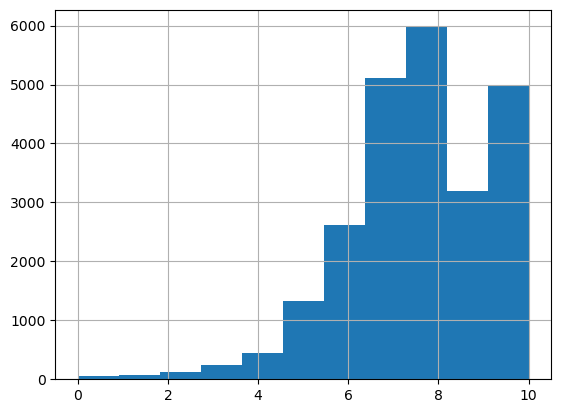

In [169]:
like_df[like_df["maxParty_untied"].notnull()]["max"].hist(bins=11)

<Axes: >

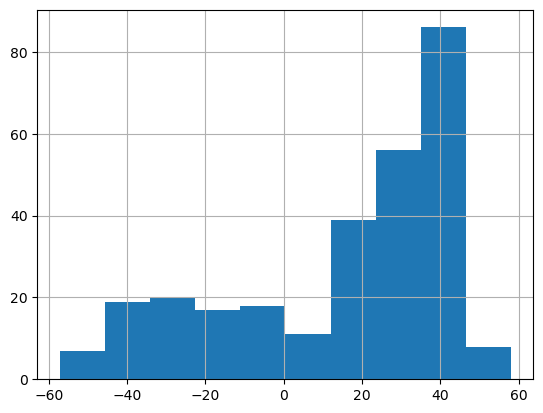

In [146]:
BES_Panel[England][(like_df["maxParty_untied"][England]=="LAB") & (BES_Panel["p_past_vote_2024"][England]=="Liberal Democrat")]\
    [['Lab24', 'LD24']].diff(axis=1)["LD24"].hist()

<Axes: >

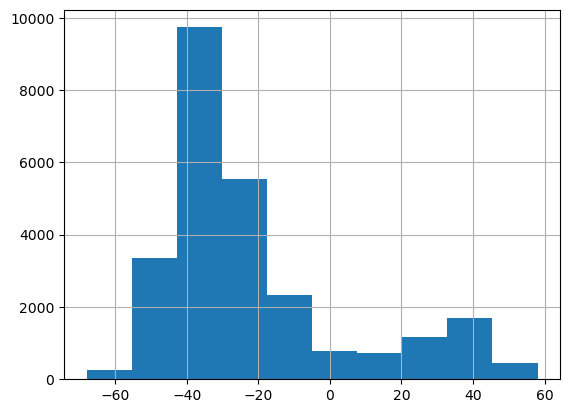

In [147]:
BES_Panel[England][['Lab24', 'LD24']].diff(axis=1)["LD24"].hist()

# yep - not perfect, but generally this is where LD >> LAB

In [228]:
BES_Panel

,waves_taken,wave1,wave2,wave3,wave4,wave5,wave6,wave7,wave8,wave9,...,c21NoWelsh,c21LanguageSomeEnglish,c21LanguageLimitedtoNoEnglish,c21ChurchofScotland,c21Catholic,c21NoQuals,c21LowerSchool,c21UpperSchool,c21Level4plus,c21Apprenticeship
id,,,,,,,,,,,,,,,,,,,,,
1,9.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,13.0,21.1,15.9,42.9,4.9
2,21.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,13.8,24.7,17.3,37.3,4.4
3,16.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,29.1,27.1,14.4,18.1,7.2
4,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,17.9,21.5,18.9,33.4,5.0
5,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,17.1,23.0,16.8,34.7,5.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123795,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,17.8,22.9,21.5,29.7,5.7
123796,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,23.4,25.2,16.5,27.4,4.8
123797,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,15.4,20.0,24.8,33.0,4.2


In [ ]:
# complete_pcon = BES_Panel[search(BES_Panel,"new_pcon_code").index].replace("",np.nan).ffill(axis=1)["new_pcon_codeW30"]
# BES_Panel["ONSConstID"] = complete_pcon
BES_Panel = BES_Panel.merge(census2024,on="ONSConstID",how='left')
BES_Panel.index= England.index

In [234]:
BES_ind = BES_reduced_with_na.index
BES_reduced_with_na["ONSConstID"] = complete_pcon.loc[BES_ind]
BES_reduced_with_na = BES_reduced_with_na.merge(census2024,on="ONSConstID",how='left')
BES_reduced_with_na.index = BES_ind


In [238]:
BES_reduced_with_na.select_dtypes('object')

,ONSConstID,ConstituencyName,Country,Region,ConstituencyType,Winner24,Second24,MPFirstName24,MPSurname24,MPGender24,IndexOfChange,Winner19,Second19
id,,,,,,,,,,,,,
6,W07000090,Cardiff North,Wales,Wales,Borough,Lab,Con,Anna,McMorrin,Female,4.3,Lab,Con
7,S14000109,Central Ayrshire,Scotland,Scotland,County,Lab,SNP,Alan,Gemmell,Male,none,SNP,Con
11,E14001185,Crewe and Nantwich,England,North West,County,Lab,Con,Connor,Naismith,Male,6.2,Con,Lab
14,E14001069,Ashford,England,South East,County,Lab,Con,Sojan,Joseph,Male,54.7,Con,Lab
18,S14000064,Alloa and Grangemouth,Scotland,Scotland,County,Lab,SNP,Brian,Leishman,Male,99.7,SNP,Con
...,...,...,...,...,...,...,...,...,...,...,...,...,...
117889,E14001215,East Surrey,England,South East,County,Con,Lab,Claire,Coutinho,Female,31.3,Con,LD
117897,E14001214,East Hampshire,England,South East,County,Con,LD,Damian,Hinds,Male,58.9,Con,LD
117903,E14001394,North East Somerset and Hanham,England,South West,County,Lab,Con,Dan,Norris,Male,89.4,Con,Lab


,Winner24,Second24,Winner19,Second19
id,,,,
6,Lab,Con,Lab,Con
7,Lab,SNP,SNP,Con
11,Lab,Con,Con,Lab
14,Lab,Con,Con,Lab
18,Lab,SNP,SNP,Con
...,...,...,...,...
117889,Con,Lab,Con,LD
117897,Con,LD,Con,LD
117903,Lab,Con,Con,Lab


MSE: 0.04, MAE: 0.11, EV: 0.73, R2: 0.73
CPU times: total: 16 s
Wall time: 2.63 s


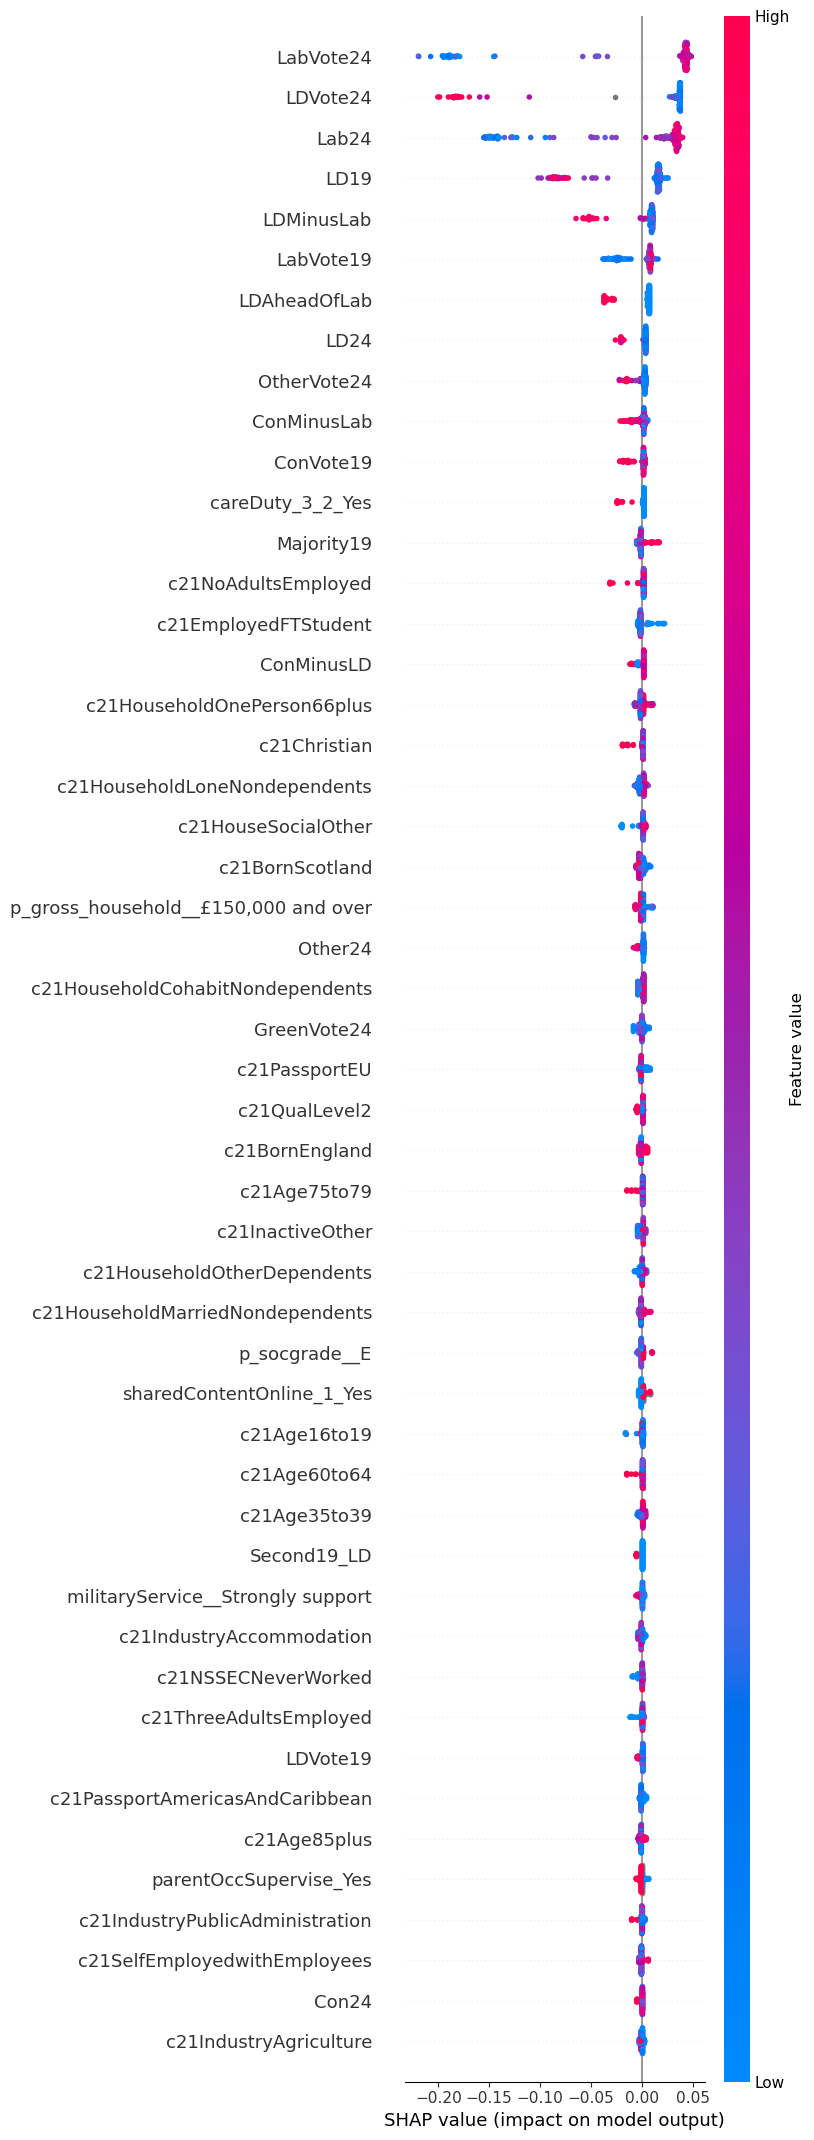

In [321]:
%%time

GE2024 = BES_Panel["p_past_vote_2024"].loc[BES_ind].astype('object')
# if "genElecTurnoutRetro" in BES_Panel.columns:
#     GE2024.loc[BES_Panel["genElecTurnoutRetro"]=="No, did not vote"] = "DNV"
replace_dict = {"Other":np.nan,"An independent candidate":np.nan,
                "Don't know":np.nan,"Scottish National Party (SNP)":np.nan,"Plaid Cymru":np.nan,
               "I would/did not vote":"DNV",'I would not vote':"DNV",
                "Labour":"LAB","Conservative":"CON","Liberal Democrat":"LD","Green Party":"GP",
                "Brexit Party/Reform UK":"REFUK",'Brexit Party':"REFUK",'United Kingdom Independence Party (UKIP)':"UKIP",
                "Change UK- The Independent Group":"TIG"}
GE2024 = GE2024.replace(replace_dict).astype('category')
# if dataset_name in ["W20_only","W9_only","W8_only","W7_only"]:
#     England = BES_Panel["country"]==1.0
# else:
#     England = BES_Panel["country"]=="England"
BES_England = BES_Panel["countryW28"]=="England"

party_colour_dict = {"CON":'blue',"LAB":'red',"GP":'green',"LD":'orange',"OTH":'black',"DNV":'grey',"REFUK":'cyan',"UKIP":'purple',"TIG":'pink'}

colour_list = [party_colour_dict[x] for x in GE2024.cat.categories]

# Does it make sense to start England-Only? Sure - just allow for expanding this later
# Ditto, drop other/ind candidate
# GE2024.value_counts()


BES_reduced_with_na["GE2024"] = GE2024.cat.codes.replace(-1,np.nan).astype('category')
BES_reduced_with_na["maxParty_untied"] = like_df["maxParty_untied"].loc[BES_ind].astype('category')
BES_reduced_with_na[search(BES_reduced_with_na,"winner|second").index] = BES_reduced_with_na[search(BES_reduced_with_na,"winner|second").index].astype('category')
BES_reduced_with_na["LDMinusLab"] = (BES_reduced_with_na["LD24"]-BES_reduced_with_na["Lab24"])
BES_reduced_with_na["ConMinusLab"] = (BES_reduced_with_na["Con24"]-BES_reduced_with_na["Lab24"])
BES_reduced_with_na["ConMinusLD"] = (BES_reduced_with_na["Con24"]-BES_reduced_with_na["LD24"])
BES_reduced_with_na["reasonForVote"] = BES_Panel.loc[BES_ind,"reasonForVoteW29"]


name = "GE2024"

mask = BES_England & (GE2024!="OTH")  & (BES_reduced_with_na["maxParty_untied"]=="LD")\
    & BES_reduced_with_na["maxParty_untied"].notnull() & GE2024.isin(["LAB","LD"]) & (BES_reduced_with_na["likeLab__Strongly like"]>=(BES_reduced_with_na["likeLD__Strongly like"]-3))\
    & (BES_reduced_with_na["likeCon__Strongly like"]<(BES_reduced_with_na["likeLD__Strongly like"]-3))\
    & (BES_reduced_with_na["reasonForVote"]=="I really preferred another party but it had no chance of winning in this constituency")

BES_reduced_with_na["GE2024"] = BES_reduced_with_na["GE2024"].apply(lambda x: np.nan if pd.isna(x) else float(x==2))
# 

stub_vars = \
["genElecTurnoutRetro","generalElectionVote","voted_ge_2024","euRefVote","p_eurefvote","p_eurefturnout","euRefDoOver","eurefTurnoutRetro",
 "turnoutUKGeneral","recallVote","voted2015",
 "eurefFinal","goodConductEURef","negotiationSpecifics","euRefExpectation","euRefCertainty","certaintyUKLeave","certaintyUKRemain",
     "campaigninfoLeave","campaigninfoRemain",# opinion about future votes, but highyl Leave/remain correlated
     "leaveTone","remainTone","proConRemain","proConLeave","betterDealEU",
 "p_past_vote","p_turnout","profile_past_vote","profile_turnout","profile_eurefturnout",
 "voteMethoda","voteMethodb","voteMethod","attemptTurnout","postalTurnout","postalApply",
     "mayorTurnout","euroElectionVote","euroTurnout","voteMethodEurope",
 "generalElectionCertainty","decidedVote", #how certain are you of your vote - strong predictor of non-voting / decided vote already
 "regretsIHaveAFew","reasonForVote","generalElectionVoteNonVoter","askedForId","disapprovalVote","normPartyVote","reasonNonVoter",
 "partyContact","participation","changeView","debate(One|Two|Three|Four|Five|Six|Seven|Eight)Watch", # campaign fx
 "noChanceCoalition","(lab|con)Partner","hungParliament",
 "voteMakesDifference", # in your local area -> marginality/strat voting
 "smallPartyWastedVote","singlePartyEffective","difficultBlameCoalition","coalitionInTune","coalitionDontDeliver",
 "partydiffconlab", # little-much diff between con and lab - questionable
 "approve(UK|Scot|Welsh)Govt",
 "change(CostLive|Crime|Immig|Economy|NHS|Education)(Lab|Con|Govt)",
 "pccVote","pccTurnout","localElection","localTurnout",
 "happyEULeave",# if we treating the Leave vote as like voting for a party ...
 "dutyToVote","dutyToVote2", # ???? are these too strong of a predictor for non-voting?
# socialPressure, normEU, electionInterest, euRefInterest ????
 
 "like","ptv","partyId","partyPreferred","bestOnMII", "leftRight", # self-positioning relative to parties
     "euID",
 "prefer(Con|Lab|Other)","majorityParty(Con|Lab|LD|Brexit)","bestPM",
 "(lab|con|govt)Handle","handleMII","handleGaza","ukGovtEconImpact","govtNatSecuritySuccess","scotGovtHandle","welshGovtHandle",
     "handleCorona","handleCoronaLab","handleUkraine","handleUkraineLab","handleEUNegotiate","handleEUNegotiateLab",
     "trustScotGovt","trustWelshGovt",
 "benchCoronaUK",# does effectively look like a "do you like the current UK govt?"
 "satDem",# also feels a little too close to evaluation of current govt

 "creditLeave","blameLeave","socialIdentityGlobalLeave","socialIdentityGlobalRemain","approveEU", # bit unclear, but creditLeave_Farage strictly identified UKIP voters
 
 
 "immig(Con|Lab|LD|SNP|PC|Brexit|Green|TIG|UKIP)","redist(Con|Lab|LD|SNP|PC|Brexit|Green|TIG|UKIP)",
     "EUIntegration(Con|Lab|LD|SNP|PC|Brexit|Green|TIG|May|Corbyn|UKIP)",
     "achieve","successReduceInequality", "_Ideas", # covers achieveReduce<issue><party>, achieveInc<issue><party>
     "(con|lab|ld|snp|pc|brexit|grn)Trust","(con|lab|ld|snp|pc|brexit|grn)Competent",
     "winConstituency(Con|Lab|LD|UKIP|TIG|Brexit|Green|SNP|PC|Ind)", # one of the few that directly referenced Ind candidates
     "lr(Con|Lab|LD|UKIP|SNP|PC|greens|TIG|Brexit)","lr(Starmer|Sunak|Corbyn|Cameron)",
     "competent(May|Corbyn|Farron|Johnson|Sunak|Starmer|Sturgeon|Wood|Farage|Lucas)",
     "integrity(May|Corbyn|Farron|Johnson|Sunak|Starmer|Sturgeon|Wood|Farage|Lucas)",
     "taxSpend(Con|Lab|LD|UKIP|SNP|PC|Green)",
     "(con|lab|brexit|brx|snp|pc|ld|grn|tig|ukip)LookAfter",
     "(con|lab|ld|snp|pc|ukip|tig|grn|brexit)United",
     "(con|lab|ld|snp|pc|ukip|grn)GovTrust",
     "(con|lab|ld|snp|pc|ukip|grn)Hope",
     "cvEcon(Con|Lab|LD|SNP|PC|Green|Brexit)",
     "responsibleDebt(Conservatives|LiberalDemocrats|Labour)|responsible(Econ|NHS|Education|CostLive|Immig|Crime)",
     "certaintyEU(Con|Lab|LD|UKIP|Green|SNP|PC)",
     "(con|lab|ld|snp|pc|ukip|grn)(Angry|Hope|Fear|Pride|None)",
     "(ld|lab|con|snp|plaid|cabinet)Support",
     "enviroGrowth(Con|Lab|LD|SNP|PC|Green|Brexit)",
     "(con|lab|ld|ukip|green)Priorities",
     # "(LD|Other|Lab|Con|Green|RUK)Vote(19|24)",
     # "(LD|Other|Lab|Con|Green|RUK)(19|24)",
 ]

stub_list = search(BES_reduced_with_na,"|".join(stub_vars)).index
drop_list = ['ONSConstID', 'ConstituencyName',
        'MPFirstName24',      'MPSurname24', ]


(explainer, shap_values, train_columns, train_index, alg,output_subfolder,metrics) = xgboost_run(
    title = "How did people vote in GE2024?(England)",
    # dataset=BES_reduced_with_na[mask].select_dtypes(['number']),
    dataset=pd.get_dummies(BES_reduced_with_na[mask].drop(drop_list,axis=1)),
    #,'category'
                                                        var_list = [name],var_stub_list = stub_list,verbosity=0,
#     classification_problem=True,
# class_names = GE2024.cat.categories ,  colour_list=colour_list,
    min_features=50)

In [318]:
search(pd.get_dummies(BES_reduced_with_na[mask].drop(drop_list,axis=1)),"reasonForVote")

reasonForVote_None of these                                                                            820
reasonForVote_I always vote that way                                                                   820
reasonForVote_I thought it was the best party                                                          820
reasonForVote_I thought that party had the best candidate                                              820
reasonForVote_I really preferred another party but it had no chance of winning in this constituency    820
reasonForVote_Other                                                                                    820
reasonForVote_Don't know                                                                               820
dtype: int64

In [322]:
mask.sum()

164

In [285]:
census2024.select_dtypes('object').columns


Index(['ONSConstID', 'ConstituencyName', 'Country', 'Region',
       'ConstituencyType', 'Winner24', 'Second24', 'MPFirstName24',
       'MPSurname24', 'MPGender24', 'IndexOfChange', 'Winner19', 'Second19'],
      dtype='object')

In [275]:
GE2024[mask].apply(lambda x: np.nan if pd.isna(x) else float(x=="LAB")).value_counts()

p_past_vote_2024
0.0    1058
1.0     394
Name: count, dtype: int64

In [276]:
BES_reduced_with_na["GE2024"].apply(lambda x: np.nan if pd.isna(x) else float(x=="LAB")).value_counts()

GE2024
0.0    22596
Name: count, dtype: int64

In [277]:
GE2024.cat.categories

Index(['CON', 'GP', 'LAB', 'LD', 'REFUK'], dtype='object')

In [290]:
search(BES_Panel,"Israel")

israelPalestineW26    30064
israelPalestineW27    30445
israelPalestineW28     7911
dtype: int64

In [292]:
import textwrap
def wrap_labels(ax, width, break_long_words=False):
    labels = []
    for label in ax.get_xticklabels():
        text = label.get_text()
        labels.append(textwrap.fill(text, width=width,
                      break_long_words=break_long_words))
    ax.set_xticklabels(labels, rotation=0)

def nice_hatch_chart(temp,title,hue="wave",value="value",hatches = ["//", "\\\\", "+","x","*","o","|","-","/",".","O","\\"]):
    fig = plt.figure(figsize=(8,4));
    ax = plt.gca()
    ax = sns.histplot(data=temp,x=value,weights="wt",stat='percent',hue=hue,multiple="dodge", common_norm=False, shrink=.8,ax=ax);
    plt.title(title);
    plt.ylabel("%");
    plt.xlabel("");

    
    # iterate through each container, hatch, and legend handle
    for container, hatch, handle in zip(ax.containers, hatches, ax.get_legend().legend_handles[::-1]):
        # update the hatching in the legend handle
        handle.set_hatch(hatch)
        # iterate through each rectangle in the container
        for rectangle in container:
            # set the rectangle hatch
            rectangle.set_hatch(hatch)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    wrap_labels(ax, 10);
    plt.show()

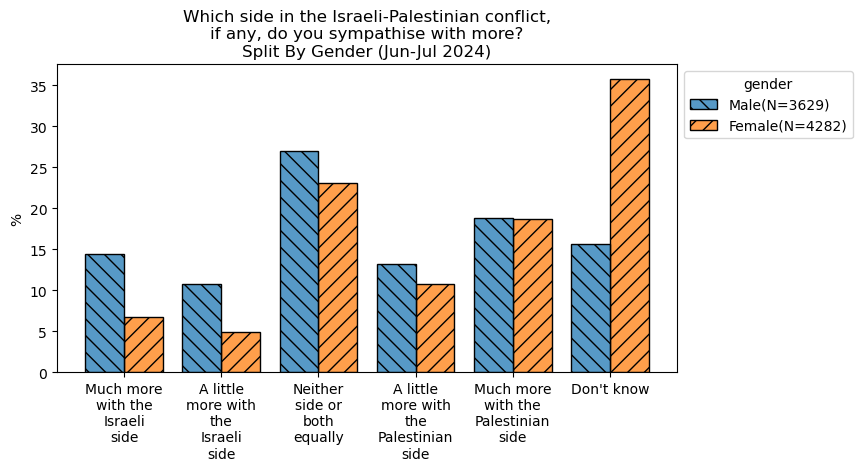

In [298]:
temp = BES_Panel[["gender","israelPalestineW28","wt_new_W28"]].dropna()
temp.columns = ["gender","israelPalestine","wt"]
vc = temp["gender"].value_counts()
temp["gender"] = temp["gender"].apply(lambda x: x+"(N="+str(vc.loc[x])+")")
title = "Which side in the Israeli-Palestinian conflict,\nif any, do you sympathise with more?\nSplit By Gender (Jun-Jul 2024)"
# temp.
nice_hatch_chart(temp,title,hue="gender",value="israelPalestine")